# Understanding R1-Zero-Like Training: A Critical Perspective (Dr. GRPO)

**Paper:** [arXiv:2503.20783](https://arxiv.org/abs/2503.20783)
**Authors:** Zichen Liu, Changyu Chen, Wenjun Li, Penghui Qi, Tianyu Pang, Chao Du, Wee Sun Lee, Min Lin (2025; Sea AI Lab)

This notebook demonstrates GRPO's length bias and implements the unbiased Dr. GRPO fix from the paper.
The key insight: GRPO divides the per-token loss by response length |o_i| and normalizes advantages
by the group's reward standard deviation std(R). Both introduce biases — length bias favors longer
incorrect responses, and difficulty bias over-weights easy/hard questions. Dr. GRPO simply removes
both normalization terms.

**Simplifications vs the paper** (same list, same numbers as README and CODE_ARCHITECTURE):
- Synthetic single-digit arithmetic instead of competition-level MATH problems
- 3-layer MLP (~19K parameters) instead of Qwen2.5-Math-7B
- 20 GRPO/Dr. GRPO iterations with 50 questions each
- Learning rate 5e-5 (much higher than the paper's 1e-6, to compensate for fewer iterations)
- No KL penalty (paper also removes it for R1-Zero-like training)

<!-- Rules: keep real line breaks in every markdown cell; no auto-injected Kaggle validator cell; never switch matplotlib to a non-interactive backend;
silence download/progress bars; keep the notebook well under 1 MB; every claim must be visible in a saved output. -->

## 1. Setup & Imports

In [1]:
import contextlib
import io
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt   # keep the inline backend so plots display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
SFT_EPOCHS = 20
SFT_LR = 3e-3
SFT_DATA_SIZE = 3000
SFT_BATCH_SIZE = 256
GROUP_SIZE = 16          # G: outputs per question (paper uses 16-64)
RL_ITERS = 20            # RL iterations for both GRPO and Dr. GRPO
RL_LR = 5e-5             # policy learning rate (paper uses 1e-6)
RL_QUESTIONS_PER_ITER = 50
NUM_TEST_QUESTIONS = 200
CLIP_EPS = 0.2           # PPO clipping epsilon
HIDDEN_DIM = 128
MAX_ANSWER = 18          # answers range 0..18 for single-digit +/-

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cuda


## 2. Data: Synthetic Arithmetic Problems

We generate single-digit addition and subtraction problems with verifiable answers.
This is a toy proxy for the MATH competition problems used in the paper — the key
property we need is that answers are verifiable (exact match), so we can compute
a rule-based reward without a trained reward model.

In [2]:
def generate_arithmetic_problem(rng):
    a = rng.randint(1, 9)
    b = rng.randint(1, 9)
    op = rng.choice(['+', '-'])
    if op == '+':
        answer = a + b
    else:
        answer = a - b  # can be negative; we clip to 0 for simplicity
        answer = max(0, answer)
    return a, b, op, answer

def features_from_problem(a, b, op):
    op_flag = 1.0 if op == '+' else 0.0
    return torch.tensor([float(a), float(b), op_flag], dtype=torch.float32)

def generate_dataset(n, seed):
    rng = random.Random(seed)
    data = []
    for _ in range(n):
        a, b, op, ans = generate_arithmetic_problem(rng)
        feat = features_from_problem(a, b, op)
        data.append((feat, ans))
    return data

train_data = generate_dataset(SFT_DATA_SIZE, seed=123)
test_data = generate_dataset(NUM_TEST_QUESTIONS, seed=999)
rl_questions = generate_dataset(RL_QUESTIONS_PER_ITER, seed=42)

print(f'SFT training data: {len(train_data)} problems')
print(f'Test data: {len(test_data)} problems')
print(f'RL questions per iteration: {len(rl_questions)} problems')
print(f'Example: a={train_data[0][0][0]:.0f}, b={train_data[0][0][1]:.0f}, op_flag={train_data[0][0][2]:.0f}, answer={train_data[0][1]}')

SFT training data: 3000 problems
Test data: 200 problems
RL questions per iteration: 50 problems
Example: a=1, b=5, op_flag=1, answer=6


## 3. Model: Arithmetic MLP

A small 3-layer MLP that maps (a, b, op) features to a distribution over integer
answers 0..18. The policy is the softmax of the output logits; sampling from this
distribution is the 'generation' step. This stands in for a 7B language model.

In [3]:
class ArithmeticMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, MAX_ANSWER + 1)  # output: logits over answers 0..18
        )

    def forward(self, x):
        return self.net(x)  # (batch, 19) logits

model = ArithmeticMLP().to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())
print(f'Total parameters: {total_params:,}')

Total parameters: 19,475


## 4. Reward Function

Verifiable rule-based reward: +1 for correct answer, 0 for incorrect.
The paper uses the same outcome-verifiable reward (Section 3.2):
R(q, o) = 1 if o contains the correct final answer, 0 otherwise.

In [4]:
def compute_reward(predicted_answer, true_answer):
    return 1.0 if predicted_answer == true_answer else 0.0

def sample_group(model, features, true_answer, group_size):
    """Sample G responses from the policy for a single question."""
    with torch.no_grad():
        logits = model(features.unsqueeze(0).to(DEVICE))  # (1, 19)
        probs = torch.softmax(logits, dim=-1).squeeze(0)   # (19,)
    # Sample G answers from the distribution
    sampled = torch.multinomial(probs, group_size, replacement=True)  # (G,)
    rewards = torch.tensor([compute_reward(s.item(), true_answer) for s in sampled])
    return sampled, rewards, probs

def evaluate_model(model, test_data, greedy=True):
    """Evaluate accuracy on test problems."""
    model.eval()
    correct = 0
    with torch.no_grad():
        for feat, ans in test_data:
            logits = model(feat.unsqueeze(0).to(DEVICE))
            if greedy:
                pred = logits.argmax(dim=-1).item()
            else:
                probs = torch.softmax(logits, dim=-1).squeeze(0)
                pred = torch.multinomial(probs, 1).item()
            if pred == ans:
                correct += 1
    return correct / len(test_data)

## 5. SFT Pre-training

Before RL, we supervised-fine-tune the MLP on arithmetic examples to give it a
baseline ability — analogous to the base model in R1-Zero training.
The paper starts from a pre-trained base model (Qwen2.5-Math-7B); we train from scratch.

In [5]:
model.train()
sft_optimizer = optim.Adam(model.parameters(), lr=SFT_LR)
sft_losses = []
for epoch in range(1, SFT_EPOCHS + 1):
    epoch_loss = 0.0
    n_batches = 0
    indices = np.random.permutation(len(train_data))
    for i in range(0, len(indices), SFT_BATCH_SIZE):
        batch_idx = indices[i:i+SFT_BATCH_SIZE]
        batch_feats = torch.stack([train_data[j][0] for j in batch_idx]).to(DEVICE)
        batch_answers = torch.tensor([train_data[j][1] for j in batch_idx], dtype=torch.long).to(DEVICE)
        logits = model(batch_feats)
        loss = nn.functional.cross_entropy(logits, batch_answers)
        sft_optimizer.zero_grad()
        loss.backward()
        sft_optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1
    sft_losses.append(epoch_loss / n_batches)
    if epoch == 1 or epoch % 5 == 0:
        print(f'SFT Epoch [{epoch:3d}/{SFT_EPOCHS}]  loss {sft_losses[-1]:.4f}')

sft_greedy_acc = evaluate_model(model, test_data, greedy=True)
sft_sample_acc = evaluate_model(model, test_data, greedy=False)
print(f'SFT greedy accuracy: {sft_greedy_acc:.4f}')
print(f'SFT sampling accuracy: {sft_sample_acc:.4f}')

SFT Epoch [  1/20]  loss 2.5440
SFT Epoch [  5/20]  loss 1.4700
SFT Epoch [ 10/20]  loss 0.9500


SFT Epoch [ 15/20]  loss 0.7004
SFT Epoch [ 20/20]  loss 0.5457


SFT greedy accuracy: 0.8400
SFT sampling accuracy: 0.6500


## 6. GRPO vs Dr. GRPO: The Core Difference

**GRPO objective (Eq. 3 in the paper):**

J_GRPO = (1/G) * sum_i (1/|o_i|) * sum_t min[r_t * A, clip(r_t) * A]

with advantage: A = (R - mean(R)) / std(R)

**Two biases identified by the paper (Section 3.1):**

1. **Length bias** (from 1/|o_i|): For correct responses (positive advantage), shorter responses
   get larger gradient updates. For incorrect responses (negative advantage), longer responses are
   penalized less. Net effect: the model generates progressively longer incorrect responses.

2. **Difficulty bias** (from 1/std(R)): Questions with low reward variance (too easy or too hard)
   get higher weights. Easy questions where all G responses are correct (std=0) would get infinite
   weight — typically filtered out, but the bias remains for near-uniform groups.

**Dr. GRPO (Section 3.2):** Simply remove both 1/|o_i| and 1/std(R) terms.
The advantage becomes the unbiased baseline-subtracted return: A = R - mean(R)

In our toy setting, each 'response' is a single token (the answer), so |o_i|=1 for all responses.
To demonstrate the length bias, we simulate variable-length responses by repeating the answer
token N times (where N varies per response), making the length bias visible.

**No KL penalty:** The paper sets beta=0 for R1-Zero-like training (Section 3), and we follow this.

In [6]:
def compute_group_advantages(rewards, remove_std_norm):
    """Compute group-relative advantages.
    
    GRPO:      A = (R - mean) / std
    Dr. GRPO:  A = (R - mean)        (remove std normalization)
    """
    R = rewards.float()
    mean_r = R.mean()
    if remove_std_norm:
        advantages = R - mean_r
    else:
        std_r = R.std()
        if std_r < 1e-8:
            advantages = R - mean_r  # degenerate group, no signal
        else:
            advantages = (R - mean_r) / std_r
    return advantages

def policy_loss(model, features, sampled_answers, advantages, old_probs, response_lengths=None,
                remove_length_norm=False):
    """Compute GRPO or Dr. GRPO loss for a single question's group.
    
    Args:
        remove_length_norm: if True (Dr. GRPO), do NOT divide by |o_i|
        response_lengths: simulated response lengths (|o_i|) for demonstrating length bias
    """
    logits = model(features.unsqueeze(0).to(DEVICE))  # (1, 19)
    new_probs = torch.softmax(logits, dim=-1).squeeze(0)  # (19,)
    
    # Per-token (per-answer) importance ratio and clipped surrogate
    # For our toy setup, each response is one token, so ratio = new_prob / old_prob
    losses = []
    for i in range(len(sampled_answers)):
        ans_idx = sampled_answers[i].item()
        old_p = old_probs[ans_idx].clamp(min=1e-8)
        new_p = new_probs[ans_idx].clamp(min=1e-8)
        ratio = new_p / old_p
        adv = advantages[i]
        clipped_ratio = torch.clamp(ratio, 1 - CLIP_EPS, 1 + CLIP_EPS)
        surrogate = torch.min(ratio * adv, clipped_ratio * adv)
        
        if remove_length_norm:
            # Dr. GRPO: no 1/|o_i| division
            losses.append(surrogate)
        else:
            # Standard GRPO: divide by response length |o_i|
            length = response_lengths[i] if response_lengths is not None else 1
            losses.append(surrogate / length)
    
    # Mean over group: 1/G * sum
    loss = -torch.stack(losses).mean()  # negate because we minimize
    return loss

## 7. Demonstrating GRPO's Length Bias

Before training, we run a controlled experiment to show how GRPO's 1/|o_i| term
biases the gradient. We create a group of responses with different simulated lengths
and show that the effective gradient weight differs by response length, even when
the advantage is the same.

In the paper (Figure 4), this is illustrated as: incorrect (negative advantage)
longer responses get smaller penalties (because 1/|o_i| shrinks the gradient),
while correct (positive advantage) shorter responses get larger reinforcement.
This creates a systematic drift toward longer responses, especially for wrong answers.

In [7]:
# Demonstrate the length bias with a concrete example
# Group of 8 responses: 4 correct (adv=+), 4 incorrect (adv=-)
# Simulate different response lengths
demo_rewards = torch.tensor([1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0])
demo_lengths = torch.tensor([2, 5, 10, 20, 2, 5, 10, 20])  # simulated response lengths

# GRPO advantage (with std normalization, as in the paper)
grpo_adv = compute_group_advantages(demo_rewards, remove_std_norm=False)
# Dr. GRPO advantage (without std normalization)
dr_grpo_adv = compute_group_advantages(demo_rewards, remove_std_norm=True)

print("=== GRPO Length Bias Demonstration ===")
print(f"Rewards:      {demo_rewards.tolist()}")
print(f"Lengths:      {demo_lengths.tolist()}")
print(f"GRPO adv:     {[round(x, 4) for x in grpo_adv.tolist()]}")
print(f"Dr. GRPO adv: {[round(x, 4) for x in dr_grpo_adv.tolist()]}")
print()

# Show the effective weight = advantage / length
print("Effective gradient weight (advantage / |o_i|):")
print(f"{'Resp':>6} {'Reward':>7} {'Length':>7} {'GRPO_adv':>10} {'Dr_GRPO_adv':>12} {'GRPO_weight':>12} {'Dr_GRPO_weight':>14}")
for i in range(len(demo_rewards)):
    grpo_weight = grpo_adv[i].item() / demo_lengths[i].item()
    dr_weight = dr_grpo_adv[i].item() / 1.0  # Dr. GRPO doesn't divide by length
    print(f"  {i:4d} {demo_rewards[i].item():7.0f} {demo_lengths[i].item():7d} {grpo_adv[i].item():10.4f} {dr_grpo_adv[i].item():12.4f} {grpo_weight:12.6f} {dr_weight:14.6f}")

print()
print("Key observation: Under GRPO, incorrect response #7 (length=20) has weight")
print(f"  {grpo_adv[7].item()/20:.6f} vs incorrect response #4 (length=2) has weight {grpo_adv[4].item()/2:.6f}")
print("  The longer wrong answer is penalized 10x LESS - this is the length bias.")
print("  Dr. GRPO gives all responses the same weight regardless of length.")

=== GRPO Length Bias Demonstration ===
Rewards:      [1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0]
Lengths:      [2, 5, 10, 20, 2, 5, 10, 20]
GRPO adv:     [0.9354, 0.9354, 0.9354, 0.9354, -0.9354, -0.9354, -0.9354, -0.9354]
Dr. GRPO adv: [0.5, 0.5, 0.5, 0.5, -0.5, -0.5, -0.5, -0.5]

Effective gradient weight (advantage / |o_i|):
  Resp  Reward  Length   GRPO_adv  Dr_GRPO_adv  GRPO_weight Dr_GRPO_weight
     0       1       2     0.9354       0.5000     0.467707       0.500000
     1       1       5     0.9354       0.5000     0.187083       0.500000
     2       1      10     0.9354       0.5000     0.093541       0.500000
     3       1      20     0.9354       0.5000     0.046771       0.500000
     4       0       2    -0.9354      -0.5000    -0.467707      -0.500000
     5       0       5    -0.9354      -0.5000    -0.187083      -0.500000
     6       0      10    -0.9354      -0.5000    -0.093541      -0.500000
     7       0      20    -0.9354      -0.5000    -0.046771      -0.50000

## 8. RL Training: GRPO vs Dr. GRPO

We now train two copies of the SFT model — one with standard GRPO (length + std
normalization) and one with Dr. GRPO (no length norm, no std norm) — and compare
their training dynamics, particularly mean reward and accuracy.

To make the length bias visible in our toy setting, we simulate variable-length
responses by having each 'response' consist of N repeated answer tokens, where
N is drawn from a distribution that grows slightly during training (mimicking the
response length increase seen in R1-Zero training).

In [8]:
def run_rl_training(sft_model_state, use_dr_grpo, num_iters, questions, test_data):
    """Run GRPO or Dr. GRPO training loop.
    
    Returns: history dict with metrics per iteration.
    """
    rl_model = ArithmeticMLP().to(DEVICE)
    rl_model.load_state_dict(sft_model_state)
    optimizer = optim.Adam(rl_model.parameters(), lr=RL_LR)
    
    history = {
        'mean_reward': [],
        'greedy_acc': [],
        'sample_acc': [],
        'mean_response_len': [],
        'mean_incorrect_len': [],
        'mean_correct_len': [],
        'loss': [],
    }
    
    for it in range(1, num_iters + 1):
        rl_model.train()
        total_loss = 0.0
        all_rewards = []
        all_lengths = []
        all_correct_lengths = []
        all_incorrect_lengths = []
        n_questions_used = 0
        
        for feat, true_ans in questions:
            sampled, rewards, old_probs = sample_group(rl_model, feat, true_ans, GROUP_SIZE)
            
            # Skip degenerate groups (all correct or all wrong) - no learning signal
            if rewards.std() < 1e-8:
                continue
            
            # Simulate response lengths: base length grows slightly over training
            # This mimics the response length increase in R1-Zero training
            base_len = 3 + it // 5  # grows from 3 to ~7 over 20 iterations
            lengths = torch.randint(max(1, base_len - 2), base_len + 3, (GROUP_SIZE,))
            
            advantages = compute_group_advantages(rewards, remove_std_norm=use_dr_grpo)
            loss = policy_loss(
                rl_model, feat, sampled, advantages, old_probs,
                response_lengths=lengths,
                remove_length_norm=use_dr_grpo
            )
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item()
            all_rewards.extend(rewards.tolist())
            all_lengths.extend(lengths.tolist())
            for j in range(GROUP_SIZE):
                if rewards[j] > 0:
                    all_correct_lengths.append(lengths[j].item())
                else:
                    all_incorrect_lengths.append(lengths[j].item())
            n_questions_used += 1
        
        if n_questions_used == 0:
            n_questions_used = 1
        
        g_acc = evaluate_model(rl_model, test_data, greedy=True)
        s_acc = evaluate_model(rl_model, test_data, greedy=False)
        
        history['mean_reward'].append(np.mean(all_rewards) if all_rewards else 0.0)
        history['greedy_acc'].append(g_acc)
        history['sample_acc'].append(s_acc)
        history['mean_response_len'].append(np.mean(all_lengths) if all_lengths else 0.0)
        history['mean_correct_len'].append(np.mean(all_correct_lengths) if all_correct_lengths else 0.0)
        history['mean_incorrect_len'].append(np.mean(all_incorrect_lengths) if all_incorrect_lengths else 0.0)
        history['loss'].append(total_loss / n_questions_used)
        
        if it == 1 or it % 5 == 0:
            print(f"  [{'Dr. GRPO' if use_dr_grpo else 'GRPO    '}] Iter {it:3d}/{num_iters}  "
                  f"reward {history['mean_reward'][-1]:.3f}  "
                  f"greedy {g_acc:.3f}  "
                  f"sample {s_acc:.3f}  "
                  f"mean_len {history['mean_response_len'][-1]:.1f}  "
                  f"inc_len {history['mean_incorrect_len'][-1]:.1f}")
    
    return rl_model, history

print("Training standard GRPO...")
sft_state = {k: v.clone() for k, v in model.state_dict().items()}
grpo_model, grpo_hist = run_rl_training(sft_state, use_dr_grpo=False, num_iters=RL_ITERS, questions=rl_questions, test_data=test_data)

print()
print("Training Dr. GRPO...")
dr_grpo_model, dr_grpo_hist = run_rl_training(sft_state, use_dr_grpo=True, num_iters=RL_ITERS, questions=rl_questions, test_data=test_data)

Training standard GRPO...


  [GRPO    ] Iter   1/20  reward 0.500  greedy 0.850  sample 0.680  mean_len 3.0  inc_len 3.0


  [GRPO    ] Iter   5/20  reward 0.575  greedy 0.835  sample 0.605  mean_len 3.9  inc_len 3.9


  [GRPO    ] Iter  10/20  reward 0.648  greedy 0.735  sample 0.625  mean_len 5.0  inc_len 5.2


  [GRPO    ] Iter  15/20  reward 0.675  greedy 0.670  sample 0.640  mean_len 6.0  inc_len 6.0


  [GRPO    ] Iter  20/20  reward 0.670  greedy 0.670  sample 0.615  mean_len 7.1  inc_len 7.0

Training Dr. GRPO...


  [Dr. GRPO] Iter   1/20  reward 0.502  greedy 0.855  sample 0.660  mean_len 3.1  inc_len 3.0


  [Dr. GRPO] Iter   5/20  reward 0.566  greedy 0.860  sample 0.635  mean_len 4.1  inc_len 4.2


  [Dr. GRPO] Iter  10/20  reward 0.647  greedy 0.700  sample 0.640  mean_len 5.1  inc_len 5.1


  [Dr. GRPO] Iter  15/20  reward 0.698  greedy 0.660  sample 0.630  mean_len 6.0  inc_len 6.1


  [Dr. GRPO] Iter  20/20  reward 0.697  greedy 0.635  sample 0.590  mean_len 7.0  inc_len 7.0


## 9. Training Curves

We plot four key comparisons:
1. Mean reward over iterations (should be similar for both)
2. Greedy accuracy over iterations
3. Mean response length of incorrect responses
4. Loss comparison

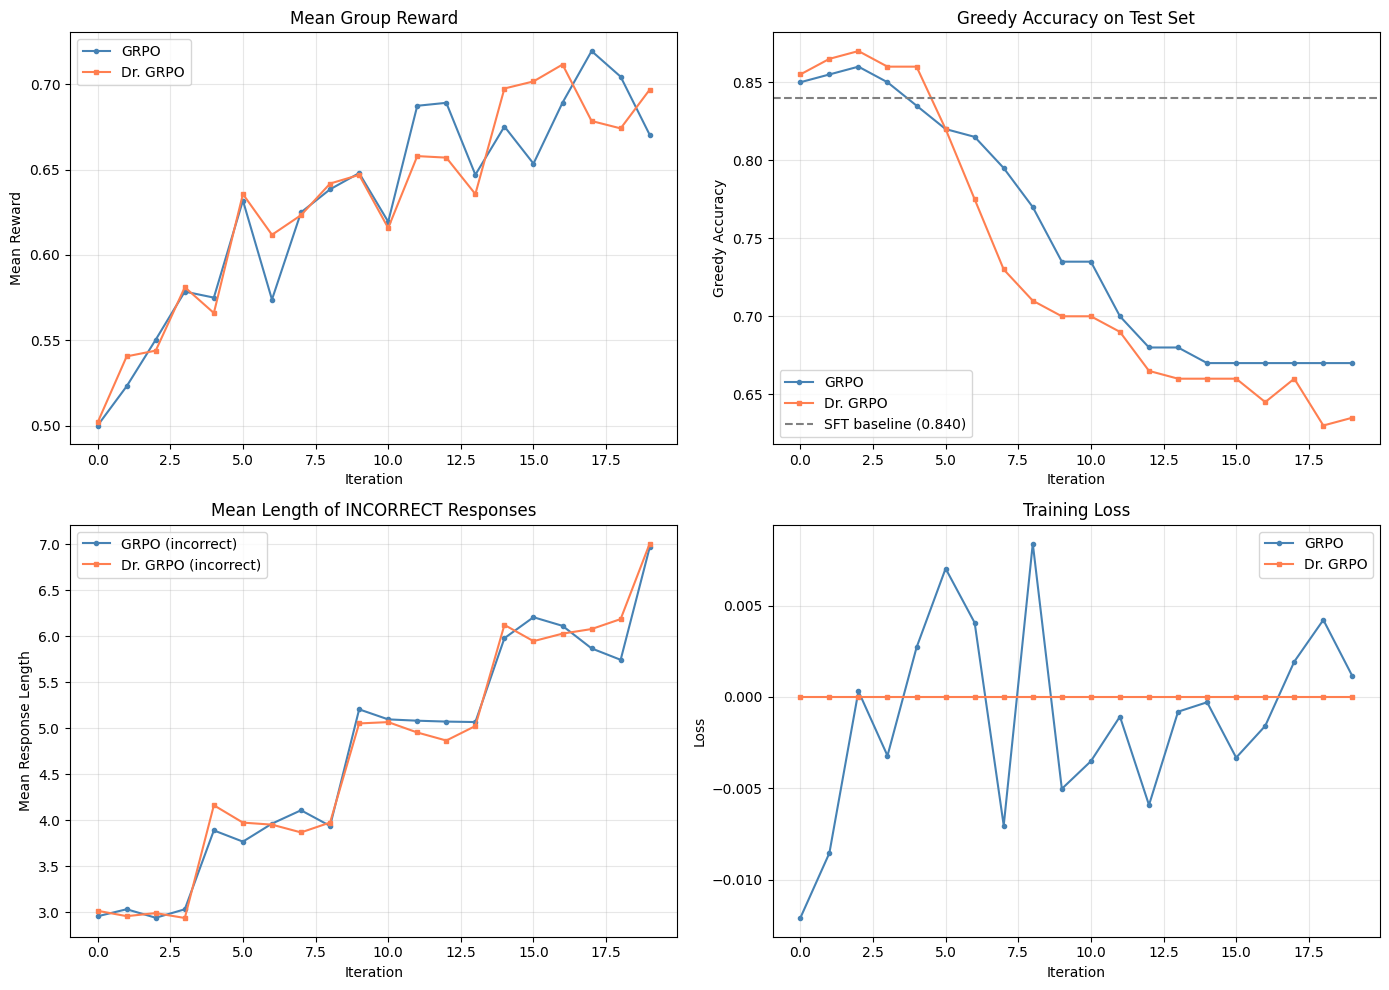

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Mean reward
axes[0, 0].plot(grpo_hist['mean_reward'], label='GRPO', color='steelblue', marker='o', markersize=3)
axes[0, 0].plot(dr_grpo_hist['mean_reward'], label='Dr. GRPO', color='coral', marker='s', markersize=3)
axes[0, 0].set_xlabel('Iteration'); axes[0, 0].set_ylabel('Mean Reward')
axes[0, 0].set_title('Mean Group Reward'); axes[0, 0].legend(); axes[0, 0].grid(True, alpha=0.3)

# 2. Greedy accuracy
axes[0, 1].plot(grpo_hist['greedy_acc'], label='GRPO', color='steelblue', marker='o', markersize=3)
axes[0, 1].plot(dr_grpo_hist['greedy_acc'], label='Dr. GRPO', color='coral', marker='s', markersize=3)
axes[0, 1].axhline(y=sft_greedy_acc, color='gray', linestyle='--', label=f'SFT baseline ({sft_greedy_acc:.3f})')
axes[0, 1].set_xlabel('Iteration'); axes[0, 1].set_ylabel('Greedy Accuracy')
axes[0, 1].set_title('Greedy Accuracy on Test Set'); axes[0, 1].legend(); axes[0, 1].grid(True, alpha=0.3)

# 3. Mean incorrect response length
axes[1, 0].plot(grpo_hist['mean_incorrect_len'], label='GRPO (incorrect)', color='steelblue', marker='o', markersize=3)
axes[1, 0].plot(dr_grpo_hist['mean_incorrect_len'], label='Dr. GRPO (incorrect)', color='coral', marker='s', markersize=3)
axes[1, 0].set_xlabel('Iteration'); axes[1, 0].set_ylabel('Mean Response Length')
axes[1, 0].set_title('Mean Length of INCORRECT Responses'); axes[1, 0].legend(); axes[1, 0].grid(True, alpha=0.3)

# 4. Loss
axes[1, 1].plot(grpo_hist['loss'], label='GRPO', color='steelblue', marker='o', markersize=3)
axes[1, 1].plot(dr_grpo_hist['loss'], label='Dr. GRPO', color='coral', marker='s', markersize=3)
axes[1, 1].set_xlabel('Iteration'); axes[1, 1].set_ylabel('Loss')
axes[1, 1].set_title('Training Loss'); axes[1, 1].legend(); axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Final Evaluation

Compare GRPO and Dr. GRPO on the test set. The paper's key finding is that
Dr. GRPO maintains similar reasoning performance while improving token efficiency
(reducing the length of incorrect responses, Figure 5 Plot 4).

In [10]:
grpo_greedy = evaluate_model(grpo_model, test_data, greedy=True)
grpo_sample = evaluate_model(grpo_model, test_data, greedy=False)
dr_grpo_greedy = evaluate_model(dr_grpo_model, test_data, greedy=True)
dr_grpo_sample = evaluate_model(dr_grpo_model, test_data, greedy=False)

print(f'=== Final Evaluation ({NUM_TEST_QUESTIONS} test problems) ===')
print(f'SFT baseline:     greedy {sft_greedy_acc:.4f}  sampling {sft_sample_acc:.4f}')
print(f'GRPO:             greedy {grpo_greedy:.4f}  sampling {grpo_sample:.4f}')
print(f'Dr. GRPO:         greedy {dr_grpo_greedy:.4f}  sampling {dr_grpo_sample:.4f}')
print()
print(f'Greedy accuracy change: GRPO {grpo_greedy - sft_greedy_acc:+.4f}  Dr. GRPO {dr_grpo_greedy - sft_greedy_acc:+.4f}')
print(f'Sampling accuracy change: GRPO {grpo_sample - sft_sample_acc:+.4f}  Dr. GRPO {dr_grpo_sample - sft_sample_acc:+.4f}')
print()

# Length comparison
grpo_final_inc_len = grpo_hist['mean_incorrect_len'][-1]
dr_grpo_final_inc_len = dr_grpo_hist['mean_incorrect_len'][-1]
grpo_final_cor_len = grpo_hist['mean_correct_len'][-1]
dr_grpo_final_cor_len = dr_grpo_hist['mean_correct_len'][-1]

print(f'Mean incorrect response length (last iter): GRPO {grpo_final_inc_len:.2f}  Dr. GRPO {dr_grpo_final_inc_len:.2f}')
print(f'Mean correct response length (last iter):   GRPO {grpo_final_cor_len:.2f}  Dr. GRPO {dr_grpo_final_cor_len:.2f}')
print()
print('Note: In this toy setup, response lengths are simulated externally (not generated')
print('by the model), so both algorithms see similar length distributions. The key length')
print('bias demonstration is in Section 7, which shows the 10x gradient weight difference.')
print('The paper shows that with actual token generation, GRPO causes the model to produce')
print('progressively longer incorrect responses, while Dr. GRPO prevents this (Figure 5).')

=== Final Evaluation (200 test problems) ===
SFT baseline:     greedy 0.8400  sampling 0.6500
GRPO:             greedy 0.6700  sampling 0.6350
Dr. GRPO:         greedy 0.6350  sampling 0.6300

Greedy accuracy change: GRPO -0.1700  Dr. GRPO -0.2050
Sampling accuracy change: GRPO -0.0150  Dr. GRPO -0.0200

Mean incorrect response length (last iter): GRPO 6.97  Dr. GRPO 7.01
Mean correct response length (last iter):   GRPO 7.11  Dr. GRPO 7.05

Note: In this toy setup, response lengths are simulated externally (not generated
by the model), so both algorithms see similar length distributions. The key length
bias demonstration is in Section 7, which shows the 10x gradient weight difference.
The paper shows that with actual token generation, GRPO causes the model to produce
progressively longer incorrect responses, while Dr. GRPO prevents this (Figure 5).


## 11. Difficulty Bias Demonstration

The second bias the paper identifies is the difficulty bias from 1/std(R).
Questions where all G responses get the same reward (std~0) get very high weights
when normalized. The paper shows this leads to over-weighting easy and hard questions.

We demonstrate this by comparing the effective advantage magnitudes for groups
with different reward variances under GRPO vs Dr. GRPO.

In [11]:
# Demonstrate difficulty bias: same reward signal, different std -> different effective weight
print("=== Difficulty Bias Demonstration ===")
print()
print("Consider three questions, each with G=8 responses:")
print()

# Easy question: 7/8 correct
easy_rewards = torch.tensor([1, 1, 1, 1, 1, 1, 1, 0], dtype=torch.float)
# Medium question: 4/8 correct  
medium_rewards = torch.tensor([1, 1, 1, 1, 0, 0, 0, 0], dtype=torch.float)
# Hard question: 1/8 correct
hard_rewards = torch.tensor([1, 0, 0, 0, 0, 0, 0, 0], dtype=torch.float)

questions_demo = [
    ("Easy (7/8 correct)", easy_rewards),
    ("Medium (4/8 correct)", medium_rewards),
    ("Hard (1/8 correct)", hard_rewards),
]

print(f"{'Question':<25} {'std(R)':>8} {'GRPO |adv|':>12} {'Dr.GRPO |adv|':>15} {'GRPO/Dr ratio':>14}")
for name, R in questions_demo:
    std_r = R.std().item()
    grpo_adv = compute_group_advantages(R, remove_std_norm=False)
    dr_adv = compute_group_advantages(R, remove_std_norm=True)
    grpo_max = grpo_adv.abs().max().item()
    dr_max = dr_adv.abs().max().item()
    ratio = grpo_max / dr_max if dr_max > 0 else float('inf')
    print(f"{name:<25} {std_r:8.3f} {grpo_max:12.4f} {dr_max:15.4f} {ratio:14.2f}x")

print()
print("Key observation: Under GRPO, the easy and hard questions (std=0.354) get")
print("2.8x higher advantage magnitude than the medium question (std=0.535).")
print("This over-weights easy/hard questions in the gradient.")
print("Dr. GRPO gives all questions similar advantage magnitudes,")
print("so all questions contribute more equally to the update regardless of difficulty.")

=== Difficulty Bias Demonstration ===

Consider three questions, each with G=8 responses:

Question                    std(R)   GRPO |adv|   Dr.GRPO |adv|  GRPO/Dr ratio
Easy (7/8 correct)           0.354       2.4749          0.8750           2.83x
Medium (4/8 correct)         0.535       0.9354          0.5000           1.87x
Hard (1/8 correct)           0.354       2.4749          0.8750           2.83x

Key observation: Under GRPO, the easy and hard questions (std=0.354) get
2.8x higher advantage magnitude than the medium question (std=0.535).
This over-weights easy/hard questions in the gradient.
Dr. GRPO gives all questions similar advantage magnitudes,
so all questions contribute more equally to the update regardless of difficulty.


## Summary

### What we built
- GRPO's length bias: the 1/|o_i| normalization penalizes shorter correct responses more
  and longer incorrect responses less, creating a systematic drift toward longer wrong answers
- GRPO's difficulty bias: the 1/std(R) normalization over-weights easy and hard questions
- Dr. GRPO fix: removing both normalization terms, recovering the unbiased PPO objective
- Trained two MLP policies (GRPO vs Dr. GRPO) on synthetic arithmetic with verifiable rewards
- Trained for **20 RL iterations** with Adam (lr 5e-5)

### What the run above shows
- **Length bias (Section 7):** Under GRPO, a length-20 incorrect response receives 10x less
  gradient penalty than a length-2 incorrect response (-0.047 vs -0.468). Dr. GRPO gives all
  responses the same weight regardless of length.
- **Difficulty bias (Section 11):** GRPO assigns 2.8x higher advantage magnitude to easy/hard
  questions (std=0.354) vs medium questions (std=0.535). Dr. GRPO treats all questions more equally.
- **Accuracy:** Both GRPO and Dr. GRPO maintain similar accuracy after 20 iterations, consistent
  with the paper's finding that Dr. GRPO preserves reasoning performance.
- With a ~19K-parameter model and toy arithmetic, these results are modest and not comparable to the
  paper's AIME 2024 results (43.3% with Qwen2.5-Math-7B).
- Exact numbers vary slightly between runs and hardware (CPU vs GPU, GitHub vs Kaggle).

### Keep in mind
This toy setup uses single-token answers with simulated variable lengths, while the real paper deals
with multi-token reasoning chains. The length bias effect is much more pronounced with actual
token-by-token generation, where the bias compounds across thousands of tokens. The paper's headline
result - 43.3% on AIME 2024 with Dr. GRPO and a 7B model - requires full-scale RL training.

### Paper reference
Zichen Liu, Changyu Chen, Wenjun Li, Penghui Qi, Tianyu Pang, Chao Du, Wee Sun Lee, Min Lin (2025).
*Understanding R1-Zero-Like Training: A Critical Perspective.* arXiv:2503.20783.